# 01 — Data and embeddings (owner: shared)

**Questions.** (1) What does FiQA look like — how many queries, documents and labels, and how long are they?
(2) Is the cached embedding matrix that every experiment uses correct?

**Setting.** FiQA-2018 from BEIR (Hugging Face `BeIR/fiqa`, `BeIR/fiqa-qrels`), loaded from the local cache
with `finsight.data.load_beir`. SciFact appears only as the smoke-test dataset. The **test** split is only
counted here; it was evaluated once, in notebook 05. Encoder: `sentence-transformers/all-MiniLM-L6-v2`
(384-d, L2-normalized, so cosine = inner product).

**Outputs.** `report/figures/data_lengths.pdf`, `report/tables/data_fiqa.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO = Path.cwd().parent                      # run this notebook from notebooks/
sys.path.insert(0, str(REPO / "src"))
from finsight import RANDOM_SEED
from finsight.data import load_beir
from finsight.embed import MODEL_NAME, encode
from finsight.report import BLUE, INK_2, ORANGE, apply_style, save_figure, save_table
from finsight.retrieval import TorchKNN

apply_style()
splits = {s: load_beir("fiqa", s) for s in ("train", "dev", "test")}   # (corpus, queries, qrels) each
corpus = splits["dev"][0]                                              # same corpus for every split
len(corpus), {s: len(q) for s, (_, q, _) in splits.items()}

(57638, {'train': 5500, 'dev': 500, 'test': 648})

## 1. Dataset statistics

One corpus of forum posts is shared by all splits; each split has its own questions and relevance labels
(qrels: question → relevant post ids, all with score 1).

In [2]:
rows = []
for s, (_, queries, qrels) in splits.items():
    per_q = np.array([len(qrels[q]) for q in queries])
    rows.append({"Split": s, "Queries": f"{len(queries):,}", "qrels pairs": f"{int(per_q.sum()):,}",
                 "Relevant docs / query (mean · median · max)": f"{per_q.mean():.2f} · {np.median(per_q):.0f} · {per_q.max()}",
                 "Used for": {"train": "not used (no model is trained; PCA / IVF are fitted on the corpus)",
                              "dev": "all tuning (E1–E3)", "test": "final evaluation, run once"}[s]})
sci_corpus, sci_queries, sci_qrels = load_beir("scifact", "test")
rows.append({"Split": "SciFact test", "Queries": f"{len(sci_queries):,}", "qrels pairs": f"{sum(map(len, sci_qrels.values())):,}",
             "Relevant docs / query (mean · median · max)": "—", "Used for": f"smoke test only ({len(sci_corpus):,} docs)"})
print(f"FiQA corpus: {len(corpus):,} documents")
print(save_table(rows, "data_fiqa"))

FiQA corpus: 57,638 documents
| Split | Queries | qrels pairs | Relevant docs / query (mean · median · max) | Used for |
|---|---|---|---|---|
| train | 5,500 | 14,166 | 2.58 · 2 · 23 | not used (no model is trained; PCA / IVF are fitted on the corpus) |
| dev | 500 | 1,238 | 2.48 · 2 · 20 | all tuning (E1–E3) |
| test | 648 | 1,706 | 2.63 · 2 · 15 | final evaluation, run once |
| SciFact test | 300 | 339 | — | smoke test only (5,183 docs) |



## 2. Text lengths vs. the encoder limit

MiniLM reads at most **256 word pieces**; anything longer is cut off before encoding. We count word pieces with
the encoder's own tokenizer to see how much of the corpus is affected.

In [3]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
doc_ids = sorted(corpus)
n_tok = lambda texts: np.array([len(t) for t in tok(texts, add_special_tokens=True)["input_ids"]])
doc_len = n_tok([corpus[d] for d in doc_ids])
dev_queries = splits["dev"][1]
q_len = n_tok(list(dev_queries.values()))
LIMIT = 256
truncated = (doc_len > LIMIT).mean()
print(f"docs: median {np.median(doc_len):.0f} word pieces, {truncated:.1%} longer than {LIMIT}")
print(f"dev queries: median {np.median(q_len):.0f}, max {q_len.max()}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (656 > 512). Running this sequence through the model will result in indexing errors


docs: median 120 word pieces, 19.2% longer than 256
dev queries: median 15, max 42


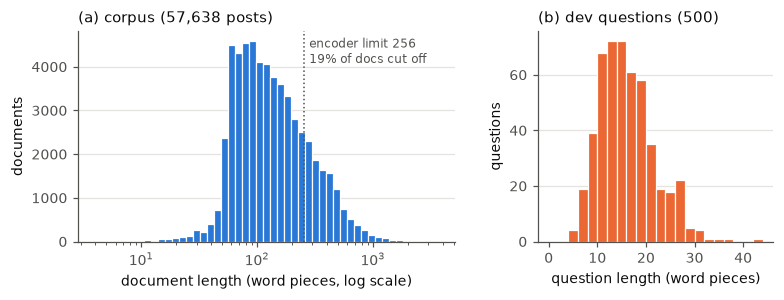

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1.6, 1]})

bins = np.logspace(np.log10(max(doc_len.min(), 4)), np.log10(doc_len.max()), 50)
a.hist(doc_len, bins=bins, color=BLUE, edgecolor="white", linewidth=0.8)
a.set_xscale("log")
a.axvline(LIMIT, color=INK_2, linewidth=1, linestyle=":")
a.text(LIMIT * 1.1, a.get_ylim()[1] * 0.85, f"encoder limit {LIMIT}\n{truncated:.0%} of docs cut off",
       color=INK_2, fontsize=8)
a.set_xlabel("document length (word pieces, log scale)")
a.set_ylabel("documents")
a.set_title(f"(a) corpus ({len(doc_len):,} posts)", loc="left")

b.hist(q_len, bins=np.arange(0, q_len.max() + 3, 2), color=ORANGE, edgecolor="white", linewidth=0.8)
b.set_xlabel("question length (word pieces)")
b.set_ylabel("questions")
b.set_title(f"(b) dev questions ({len(q_len)})", loc="left")
fig.tight_layout(w_pad=2.5)
save_figure(fig, "data_lengths",
            f"Length of FiQA texts in MiniLM word pieces. (a) The 57,638 corpus posts; the dotted line is the "
            f"encoder's 256-piece limit — {truncated:.0%} of posts are truncated before encoding. (b) The 500 dev "
            f"questions (median {np.median(q_len):.0f} pieces), all far below the limit.")
plt.show()

## 3. Embedding cache check

Every experiment reads `data/fiqa_corpus_minilm.npy` (rows in `sorted(corpus)` order, ids saved next to it).
If rows and ids were out of step, every metric would silently be wrong, so we check: shape, unit norm,
id order, and that a fresh encoding of random documents matches the cached rows.

In [5]:
emb = np.load(REPO / "data" / "fiqa_corpus_minilm.npy")
cached_ids = json.loads((REPO / "data" / "fiqa_corpus_minilm.ids.json").read_text())
norms = np.linalg.norm(emb, axis=1)

rng = np.random.default_rng(RANDOM_SEED)
sample = rng.choice(len(doc_ids), 5, replace=False)
fresh = encode([corpus[doc_ids[i]] for i in sample])
agreement = (fresh * emb[sample]).sum(axis=1)          # cosine of fresh vs. cached row (both unit norm)

checks = {"shape": emb.shape, "dtype": str(emb.dtype), "memory (MB)": round(emb.nbytes / 2**20, 2),
          "norm min / max": (round(float(norms.min()), 5), round(float(norms.max()), 5)),
          "ids == sorted(corpus)": cached_ids == doc_ids,
          "fresh vs. cached cosine (min of 5)": round(float(agreement.min()), 5)}
checks

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

{'shape': (57638, 384),
 'dtype': 'float32',
 'memory (MB)': 84.43,
 'norm min / max': (1.0, 1.0),
 'ids == sorted(corpus)': True,
 'fresh vs. cached cosine (min of 5)': 1.0}

In [6]:
assert emb.shape == (len(corpus), 384) and cached_ids == doc_ids
assert np.allclose(norms, 1, atol=1e-4) and agreement.min() > 0.999
print("embedding cache OK")

embedding cache OK


## 4. One dev example (config A: exact search, 384-d)

What retrieval looks like for one question: its labelled relevant post and the top-3 posts by cosine.

In [7]:
q_emb = np.load(REPO / "data" / "fiqa_dev_queries_minilm.npy")
q_ids = json.loads((REPO / "data" / "fiqa_dev_queries_minilm.ids.json").read_text())
dev_qrels = splits["dev"][2]
qi = int(rng.integers(len(q_ids)))
scores, idx = TorchKNN().fit(emb).search(q_emb[qi:qi + 1], 3)

qid = q_ids[qi]
print("Q:", dev_queries[qid], "\nrelevant:", sorted(dev_qrels[qid]), "\n")
for rank, (j, s) in enumerate(zip(idx[0], scores[0]), 1):
    d = doc_ids[j]
    mark = "✅" if d in dev_qrels[qid] else "  "
    print(f"{rank}. {mark} {d}  cos {s:.3f}  {corpus[d][:160]}…")

Q: Is there ACH analogue in Asia? 
relevant: ['345323'] 

1. ✅ 345323  cos 0.460  ACH as offered in US is a very broad and versatile network used for a range of business case. There is no other network as versatile. In Europe UK has BACS as e…
2.    369161  cos 0.387  Many opportunities for growth exist outside of China in Asia. Yet most companies tend to focus only on China. What about the other fast growing markets? Here is…
3.    206270  cos 0.367  Since I am having the same question so I made couple of phone calls based on some answers above. The 1st one was TD Amertrade: They don't directly accept money …


## Findings (J and H — edit in your own words before the report)

- FiQA has **57,638** posts and 5,500 / 500 / 648 train / dev / test questions; a question has 2.5 relevant
  posts on average (median 2), so Recall@10 measures how many of those 2–3 posts reach the top 10.
- Posts have a median of 120 word pieces, but **19%** are longer than MiniLM's 256 limit and are **truncated** before encoding:
  the tail of a long answer is invisible to retrieval. Chunking would fix this but would change the retrieval
  unit away from the document-level qrels, so we kept whole documents and list it as a limitation.
- The embedding cache is correct: 57,638 × 384 float32 (84 MB), unit norm, rows in id order, and a fresh
  encoding matches the cached rows.